## Danish Ais 02 Passage And Holding Area (Flag 2)

### Dataset Overview
The main table contains timestamped vessel positions and AIS-style movement attributes. The vessel table contains stable vessel attributes shared across trajectory segments.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Examine the operating conditions of the given vessels passing through the corridor on two days and compare them.

Role: Maritime traffic analyst


Category: Maritime corridor and vessel behavior

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the number of vessels passing through the corridor differ between the two days?

#### Analysis action

Compare the two-hour profile of distinct corridor entries, rather than using only the daily total.

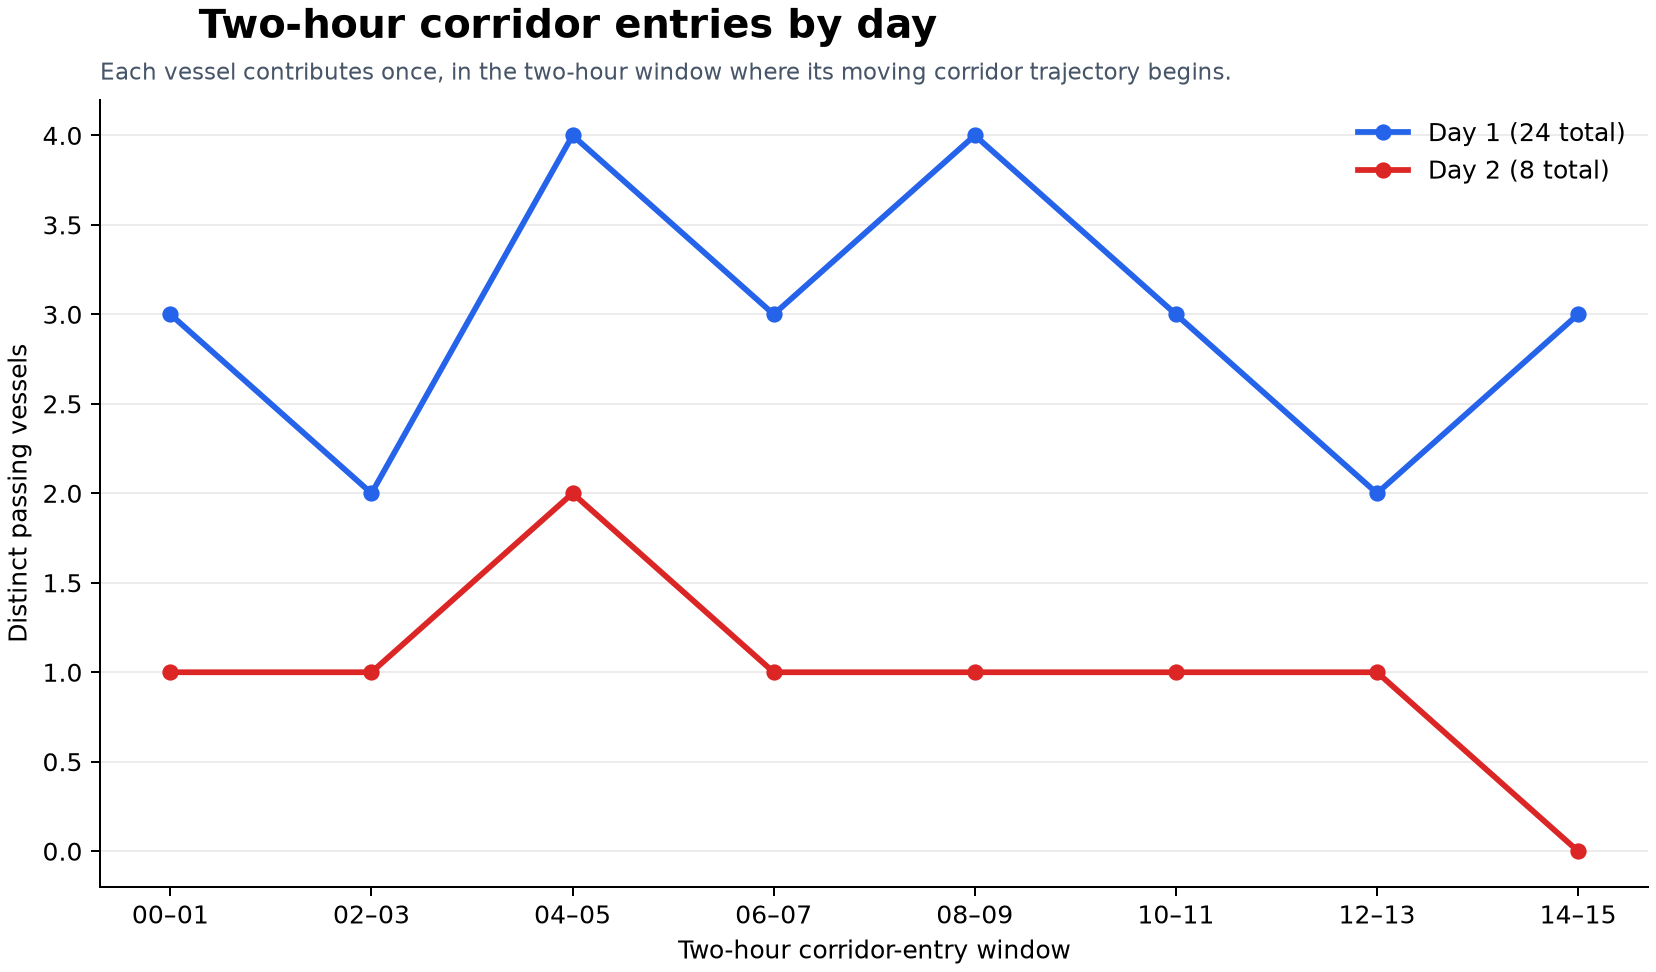

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df[d['sog']>=5].copy(); d['timestamp']=pd.to_datetime(d['timestamp']); first=d.groupby(['day','trajectory_id'])['timestamp'].min().reset_index(); first['two_hour_window']=(first.timestamp.dt.hour//2)*2; profile=first.groupby(['day','two_hour_window']).size().unstack(0,fill_value=0); profile.plot(marker='o'); plt.ylabel('distinct corridor entries'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/daily_passage_counts.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temporal_comparison",
  "insight": "The first day has three times as many vessels passing clearly through the corridor as the second day.",
  "insight_value": {
    "day_1_passage_vessels": 24,
    "day_2_passage_vessels": 8,
    "ratio": 3.0
  },
  "plot": {
    "plot_type": "time_window_line_chart",
    "title": "Two-hour corridor entries by day",
    "file": "visualizations/daily_passage_counts.png",
    "description": "The plot provides the visual comparison needed for this question."
  },
  "question": "How does the number of vessels passing through the corridor differ between the two days?",
  "actionable_insight": "Compare the two-hour profile of distinct corridor entries, rather than using only the daily total.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df[d['sog']>=5].copy(); d['timestamp']=pd.to_datetime(d['timestamp']); first=d.groupby(['day','trajectory_id'])['timestamp'].min().reset_index(); first['two_hour_window']=(first.timestamp.dt.hour//2)*2; profile=first.groupby(['day','two_hour_window']).size().unstack(0,fill_value=0); profile.plot(marker='o'); plt.ylabel('distinct corridor entries'); plt.show()",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "vessel_id",
    "point_speed"
  ]
}

### **Question 2**: Do vessels use the corridor in the same direction on both days?

#### Analysis action

Infer direction from ordered trajectory endpoints and interpret it relative to the mapped corridor orientation.

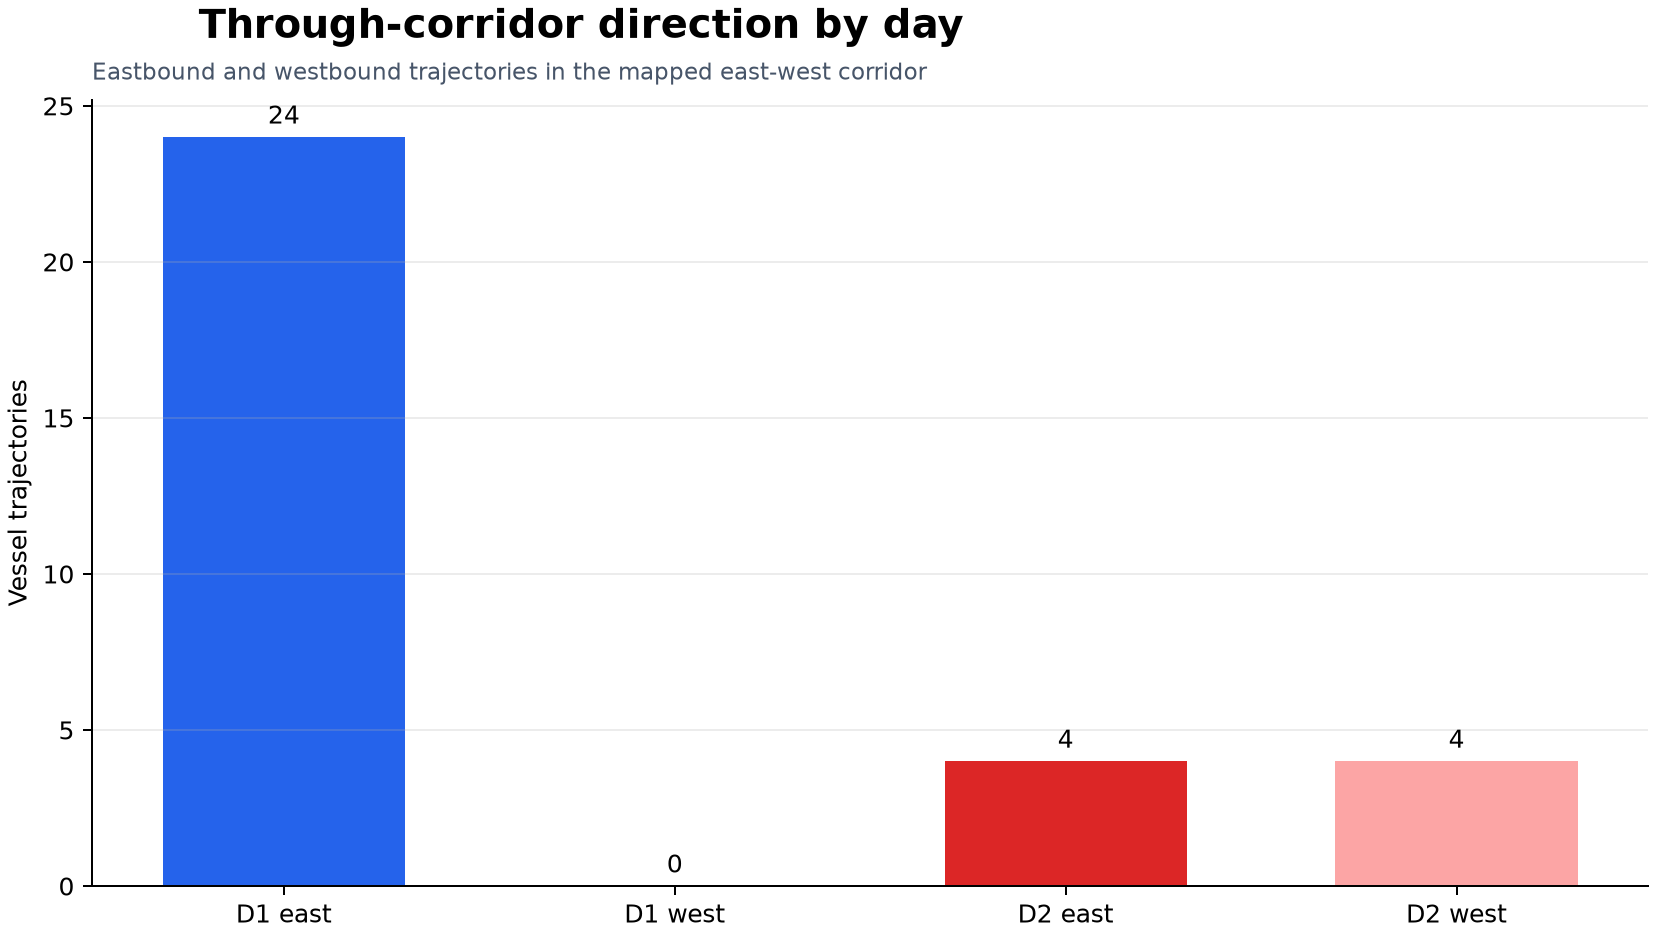

In [ ]:
import pandas as pd
d=df.copy(); d=d[d['sog']>=5]; g=d.groupby(['day','trajectory_id']); direction=g['lon'].agg(['first','last']); direction['direction']=direction.apply(lambda r:'eastbound' if r['last']>=r['first'] else 'westbound',axis=1); print(direction.groupby(['day','direction']).size())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/direction_comparison.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "directional_comparison",
  "insight": "On the first day, nearly all corridor passages are eastbound along the mapped east-west corridor, whereas the second day contains a much more balanced mix of eastbound and westbound passages.",
  "insight_value": {
    "corridor_orientation": "east-west",
    "day_1": "predominantly eastbound",
    "day_2": "balanced directions"
  },
  "plot": {
    "plot_type": "direction_chart",
    "title": "Through-corridor direction by day",
    "file": "visualizations/direction_comparison.png",
    "description": "The plot provides the visual comparison needed for this question."
  },
  "question": "Do vessels use the corridor in the same direction on both days?",
  "actionable_insight": "Infer direction from ordered trajectory endpoints and interpret it relative to the mapped corridor orientation.",
  "code": "import pandas as pd\nd=df.copy(); d=d[d['sog']>=5]; g=d.groupby(['day','trajectory_id']); direction=g['lon'].agg(['first','last']); direction['direction']=direction.apply(lambda r:'eastbound' if r['last']>=r['first'] else 'westbound',axis=1); print(direction.groupby(['day','direction']).size())",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "vessel_id",
    "point_speed"
  ]
}

### **Question 3**: How does anchoring near the corridor differ between the two days?

#### Analysis action

Compare day totals while retaining the ship-type segments that make up each total.

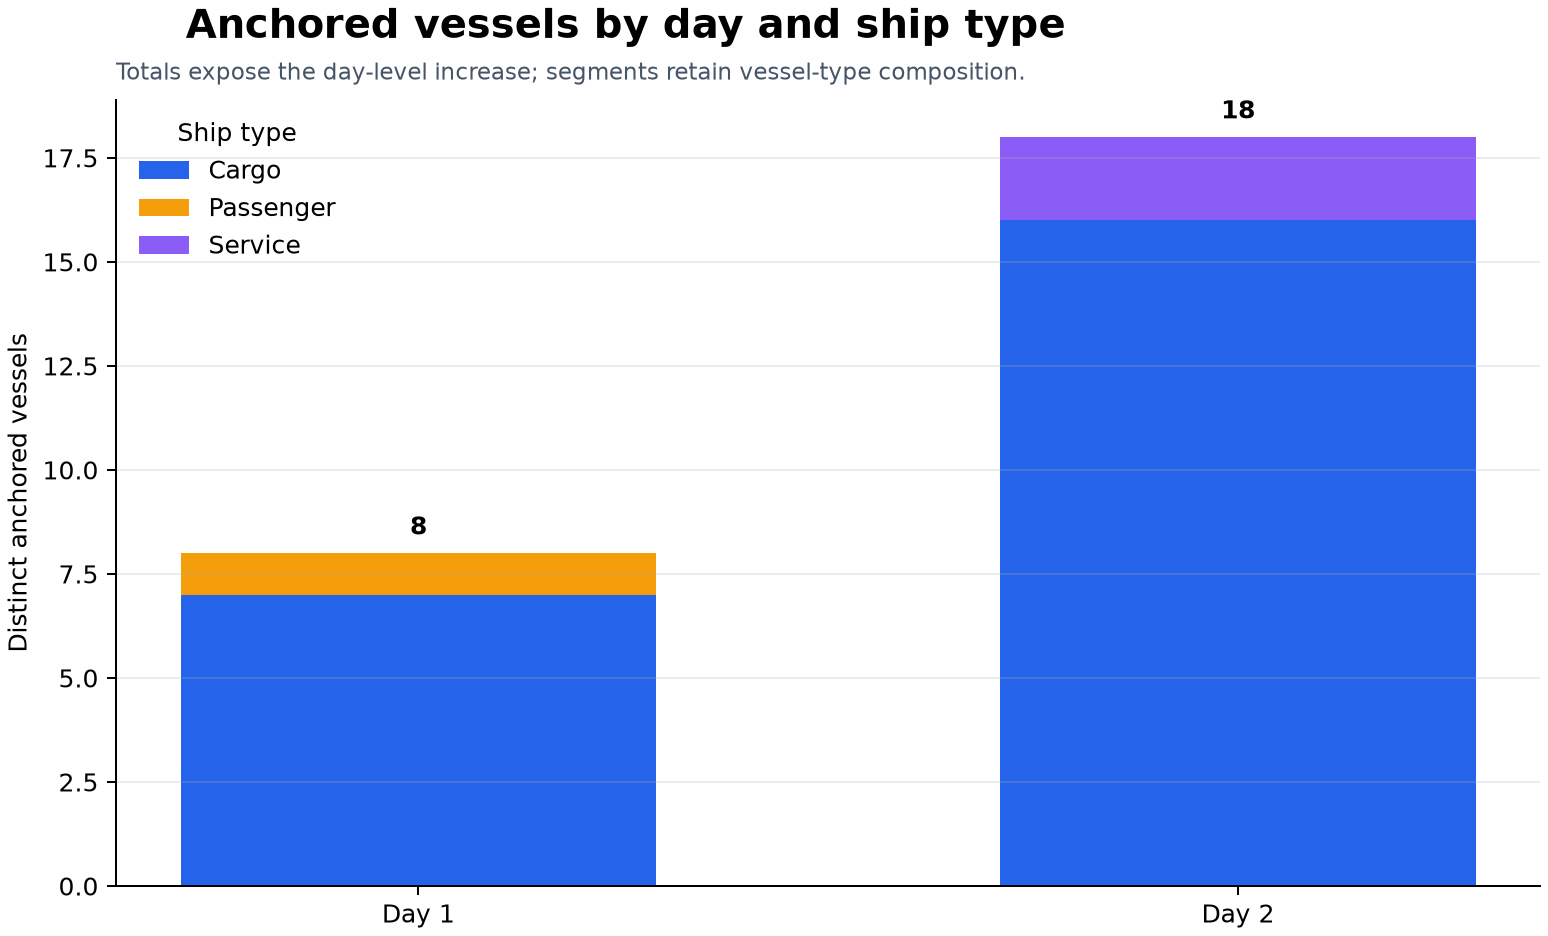

In [ ]:
import pandas as pd
d=df[df['nav_status'].eq('At anchor')].drop_duplicates('trajectory_id'); print(pd.crosstab(d['day'],d['ship_type'],margins=True))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/anchored_vessel_counts.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "temporal_comparison",
  "insight": "The second day has more than twice as many vessels anchored near the corridor as the first day.",
  "insight_value": {
    "day_1_anchored": 8,
    "day_2_anchored": 18,
    "ratio": 2.25
  },
  "plot": {
    "plot_type": "stacked_type_composition",
    "title": "Anchored vessels by day and ship type",
    "file": "visualizations/anchored_vessel_counts.png",
    "description": "The plot provides the visual comparison needed for this question."
  },
  "question": "How does anchoring near the corridor differ between the two days?",
  "actionable_insight": "Compare day totals while retaining the ship-type segments that make up each total.",
  "code": "import pandas as pd\nd=df[df['nav_status'].eq('At anchor')].drop_duplicates('trajectory_id'); print(pd.crosstab(d['day'],d['ship_type'],margins=True))",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "gps_position",
    "navigation_status",
    "vessel_id",
    "ship_type"
  ]
}

### **Question 4**: Which ship types dominate the anchored vessels on each day?

#### Analysis action

Compare ship-type composition within the anchored subset separately by day and retain small non-cargo categories.

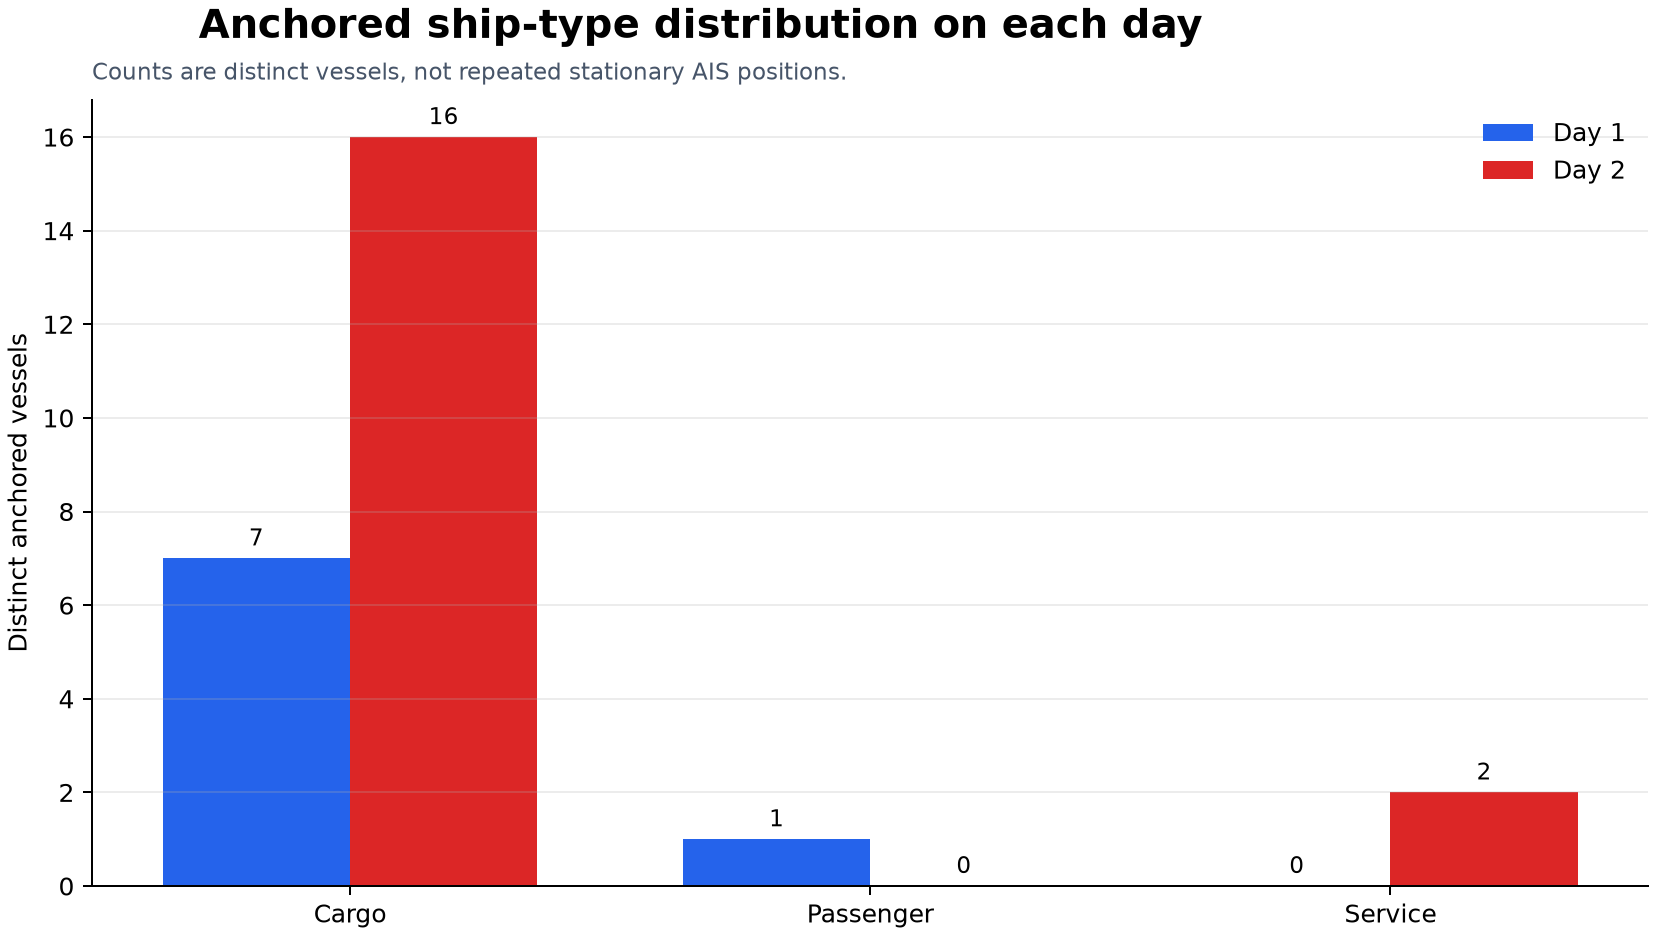

In [ ]:
import pandas as pd
d=df[df['nav_status'].eq('At anchor')].drop_duplicates('trajectory_id'); print(pd.crosstab(d['day'], d['ship_type']))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/anchored_ship_types.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "categorical_comparison",
  "insight": "On both days, anchored vessels are predominantly classified as Cargo, with only a small number assigned to other ship-type categories.",
  "insight_value": {
    "subset": "At anchor",
    "dominant_category": "Cargo"
  },
  "plot": {
    "plot_type": "grouped_bar_chart",
    "title": "Anchored ship-type distribution on each day",
    "file": "visualizations/anchored_ship_types.png",
    "description": "The plot provides the visual comparison needed for this question."
  },
  "question": "Which ship types dominate the anchored vessels on each day?",
  "actionable_insight": "Compare ship-type composition within the anchored subset separately by day and retain small non-cargo categories.",
  "code": "import pandas as pd\nd=df[df['nav_status'].eq('At anchor')].drop_duplicates('trajectory_id'); print(pd.crosstab(d['day'], d['ship_type']))",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trajectory_timestamp",
    "navigation_status",
    "ship_type",
    "vessel_id"
  ]
}

### **Question 5**: Which vessels recur across the two days, and do they repeat passage or anchoring behavior?

#### Analysis action

Match vessels by their stable vessel identifier before comparing their day-specific movement state.

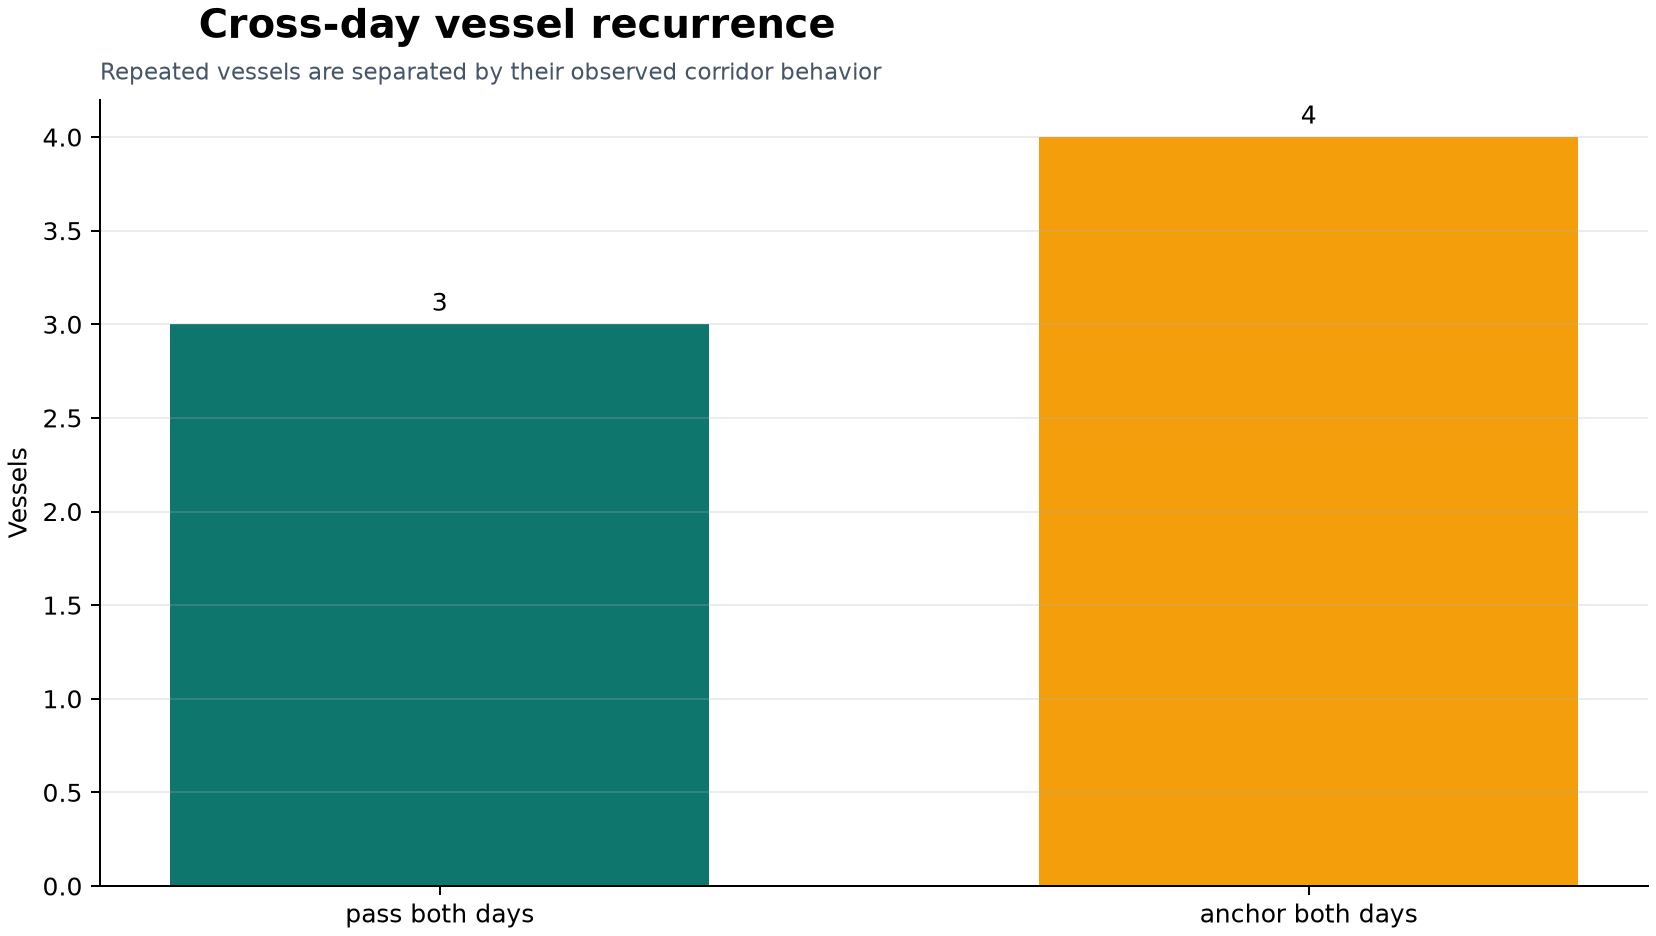

In [ ]:
import pandas as pd
d=df.copy(); days=d.groupby('vessel_id')['day'].nunique(); repeated=days[days==2].index; a=d[d['vessel_id'].isin(repeated)]; print(a.groupby(['vessel_id','day'])['nav_status'].first())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/cross_day_recurrence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "cross_day_recurrence",
  "insight": "Only a small number of vessels pass through the corridor on both days, while four vessels—about half of the first day's anchored vessels—are anchored near the corridor on both days.",
  "insight_value": {
    "recurring_passage_vessels": 3,
    "recurring_anchored_vessels": 4,
    "share_of_day_1_anchored": 0.5
  },
  "plot": {
    "plot_type": "overlap_chart",
    "title": "Cross-day vessel recurrence",
    "file": "visualizations/cross_day_recurrence.png",
    "description": "The plot provides the visual comparison needed for this question."
  },
  "question": "Which vessels recur across the two days, and do they repeat passage or anchoring behavior?",
  "actionable_insight": "Match vessels by their stable vessel identifier before comparing their day-specific movement state.",
  "code": "import pandas as pd\nd=df.copy(); days=d.groupby('vessel_id')['day'].nunique(); repeated=days[days==2].index; a=d[d['vessel_id'].isin(repeated)]; print(a.groupby(['vessel_id','day'])['nav_status'].first())",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "trajectory_timestamp",
    "gps_position",
    "navigation_status"
  ]
}

### Summary of Findings (Flag 2)

The two-day case contrasts a busy, predominantly eastbound passage day with a quieter, directionally balanced day that has substantially more anchoring near the corridor and limited vessel recurrence.